In [3]:
!apt-get install -y tesseract-ocr
!pip install pytesseract
import cv2
import pytesseract
from matplotlib import pyplot as plt

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
tesseract-ocr is already the newest version (5.3.4-1build5).
0 upgraded, 0 newly installed, 0 to remove and 2 not upgraded.


In [26]:
import os
import urllib.request
import cv2

# Using a highly stable and verified image containing text from Google's servers
image_path = "/content/sample_ocr_image.png"
url = "https://www.google.com/images/branding/googlelogo/1x/googlelogo_color_272x92dp.png"

try:
    # Clean up any failed downloads
    if os.path.exists(image_path):
        os.remove(image_path)

    print("Downloading a sample image for OCR processing...")
    opener = urllib.request.build_opener()
    opener.addheaders = [('User-agent', 'Mozilla/5.0')]
    urllib.request.install_opener(opener)
    urllib.request.urlretrieve(url, image_path)

    image = cv2.imread(image_path)
    if image is None:
        print("Error: Failed to load the downloaded image.")
    else:
        image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        print("Image successfully downloaded, loaded, and converted to RGB!")
except Exception as e:
    print(f"An error occurred while downloading or loading the image: {e}")

Image successfully downloaded, loaded, and converted to RGB!


Grayscale Image:


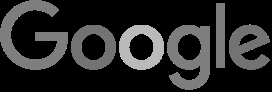

In [27]:
from google.colab.patches import cv2_imshow

if 'image' in locals() and image is not None:
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    print("Grayscale Image:")
    cv2_imshow(gray)
else:
    print("Error: 'image' is not defined or failed to load. Please make sure the image file exists and is loaded successfully in cell sXweGT3FH8V2 first.")

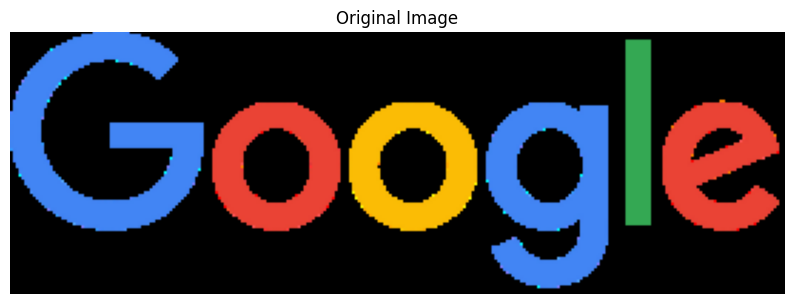

In [28]:
if 'image_rgb' in locals() and image_rgb is not None:
    plt.figure(figsize=(10, 6))
    plt.imshow(image_rgb)
    plt.title("Original Image")
    plt.axis("off")
    plt.show()
else:
    print("Error: 'image_rgb' is not defined. Please make sure the image file is successfully loaded and converted in cell sXweGT3FH8V2 first.")

In [29]:
extracted_text = pytesseract.image_to_string(image_rgb)
print(" Extracted Text:\n")
print(extracted_text)

 Extracted Text:

Google



In [30]:
data = pytesseract.image_to_data(image_rgb, output_type=pytesseract.Output.DICT)

n_boxes = len(data['level'])
for i in range(n_boxes):
    (x, y, w, h) = (data['left'][i], data['top'][i], data['width'][i], data['height'][i])
    cv2.rectangle(image_rgb, (x, y), (x + w, y + h), (255, 0, 0), 2)

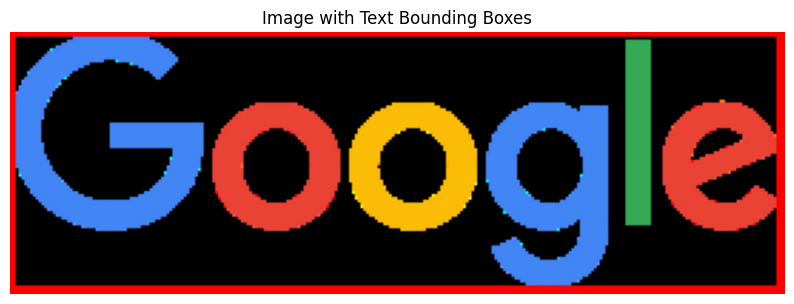

In [31]:
plt.figure(figsize=(10, 6))
plt.imshow(image_rgb)
plt.title("Image with Text Bounding Boxes")
plt.axis("off")
plt.show()